In [ ]:
# run with conda env vbb
2+2

4

In [2]:
import os
import json
from pathlib import Path

import random
import pandas as pd
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
from tqdm import tqdm


import ast
import re

import nltk
from nltk.stem import WordNetLemmatizer


# ssv2

Example:
| id | label | template | placeholders |
| --- | --- | --- | --- |
| 42326 | spreading margarine onto bread | Spreading [something] onto [something] | [margarine, bread] |

- Train / val set counts and percentage splits
- Top15/Bottom15 classes (classes are 'templates' in ssv2)
- Distribution of classes in the train/val sets

Noun analysis: 
- (nouns are 'placeholders' in ssv2)
- Lemmatizing verbs (we started with 171 unique templates and are now down to 51 verb classes)
- Examples have 1,2 or 3 nouns. I expanded the dataset to make a row for noun_1, noun_2 and noun_3. noun_1 is direct object of sentence usually so most analysis is restricted to it.
- Conditional probabilities P(Noun | Verb) (what nouns dominate a given action)
- Conditional Probabilities P(Verb | Noun) (what verbs dominate a given noun)
- Co-occurence matrix of top nouns and direct-object-nouns (Plot)

In [3]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2"
labels_dir = Path(ssv2_path) / "labels"
labels_dir

PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels')

In [4]:
# SSv2 annotations use train.json and validation.json
train_file = labels_dir / "train.json"
val_file = labels_dir / "validation.json"

with open(train_file, 'r') as f:
    train_raw = json.load(f)

with open(val_file, 'r') as f:
    val_raw = json.load(f)

train_raw[0:2] # train_raw is a list. i am printing first 2 elements which are training examples.

[{'id': '78687',
  'label': 'holding potato next to vicks vaporub bottle',
  'template': 'Holding [something] next to [something]',
  'placeholders': ['potato', 'vicks vaporub bottle']},
 {'id': '42326',
  'label': 'spreading margarine onto bread',
  'template': 'Spreading [something] onto [something]',
  'placeholders': ['margarine', 'bread']}]

In [5]:
df_train = pd.DataFrame(train_raw)
df_train['split'] = 'train'

df_val = pd.DataFrame(val_raw)
df_val['split'] = 'val'

df = pd.concat([df_train, df_val], ignore_index=True)
df.head(2)

,id,label,template,placeholders,split
0,78687,holding potato next to vicks vaporub bottle,Holding [something] next to [something],"[potato, vicks vaporub bottle]",train
1,42326,spreading margarine onto bread,Spreading [something] onto [something],"[margarine, bread]",train


In [9]:
print(f"Total Train Samples: {len(df_train):,}")
print(f"Total Val Samples:   {len(df_val):,}")
df.split.value_counts(1)*100

Total Train Samples: 168,913
Total Val Samples:   24,777


split
train    87.20791
val      12.79209
Name: proportion, dtype: float64

In [7]:
print(f"Unique Templates:{df['template'].nunique()}")

Unique Templates:174


/tmp/ipykernel_3971264/3500712344.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top15, y='template', x='count', palette='viridis', ax=ax)


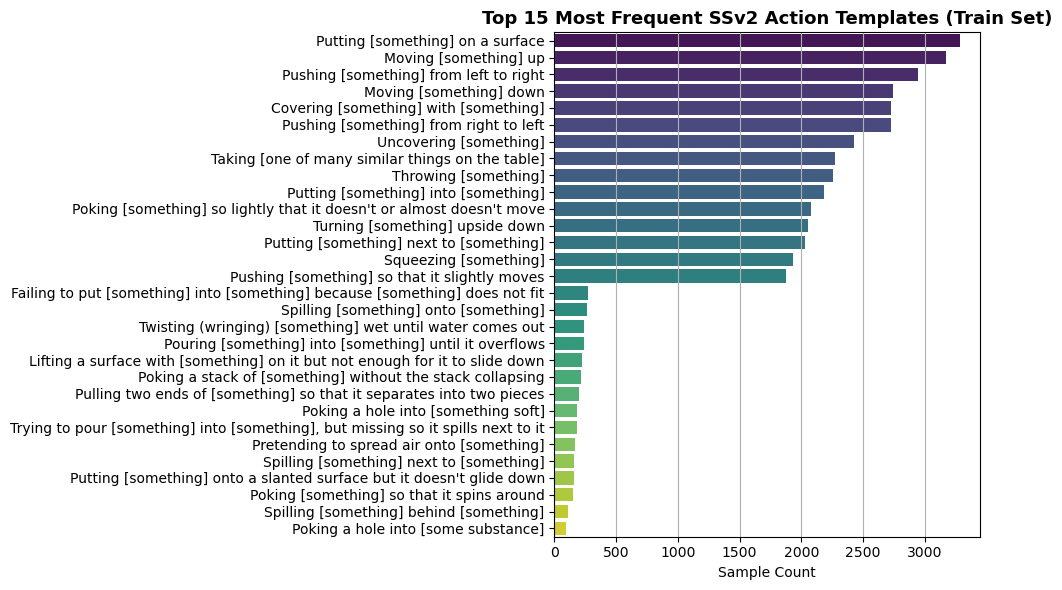

In [8]:
# top 15 and bottom 15 class counts (Train)
train_counts = df_train['template'].value_counts()

top15 = train_counts.head(15).reset_index()
bottom15 = train_counts.tail(15).reset_index()
top15 = pd.concat([top15, bottom15]).reset_index(drop=True)
top15.columns = ['template', 'count']

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(zorder=0)
sns.barplot(data=top15, y='template', x='count', palette='viridis', ax=ax)

ax.set_title("Top 15 Most Frequent SSv2 Action Templates (Train Set)", fontsize=13, fontweight='bold')
ax.set_xlabel("Sample Count")
ax.set_ylabel('')  # Clear y-axis label text

plt.tight_layout()
plt.show()

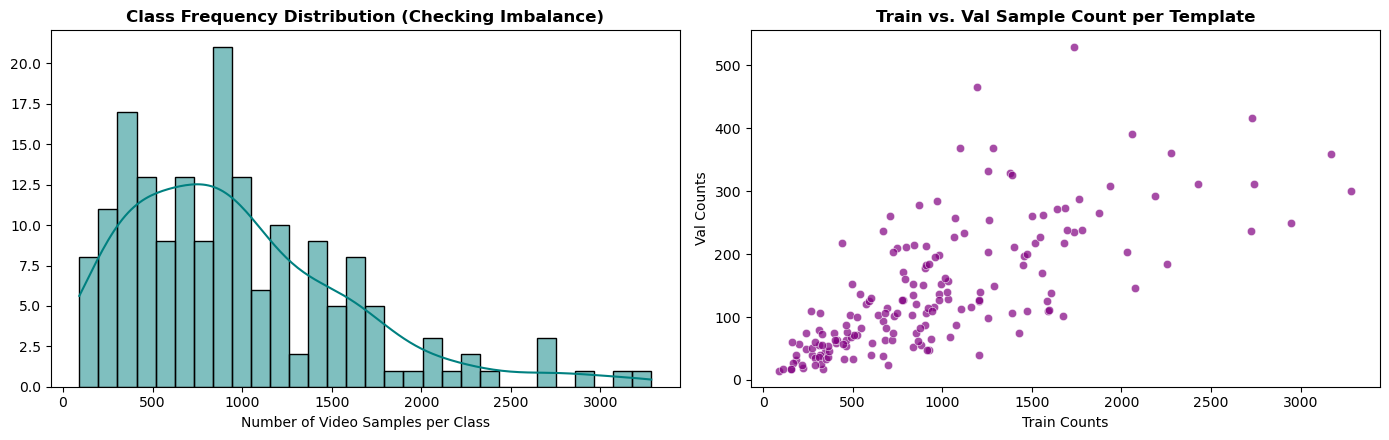

In [10]:
## Gemini AI code below: Long-Tail Distribution & Train/Val Split Consistency for ssv2 dataset
# Group class frequencies by split
class_counts = df.groupby(['template', 'split']).size().reset_index(name='count')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution curve (Long-tail inspection)
sns.histplot(data=df_train['template'].value_counts(), kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title("Class Frequency Distribution (Checking Imbalance)", fontweight='bold')
axes[0].set_xlabel("Number of Video Samples per Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts across classes
sns.scatterplot(
    data=df.groupby('template')['split'].value_counts().unstack().fillna(0),
    x='train', y='val', alpha=0.7, color='purple', ax=axes[1]
)
axes[1].set_title("Train vs. Val Sample Count per Template", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()

In [11]:
pd.set_option('display.width', 10000)
print(df[0:2])

      id                                        label                                 template                    placeholders  split
0  78687  holding potato next to vicks vaporub bottle  Holding [something] next to [something]  [potato, vicks vaporub bottle]  train
1  42326               spreading margarine onto bread   Spreading [something] onto [something]              [margarine, bread]  train


In [12]:
# How many placeholders per example on average?
df.placeholders.apply(len).value_counts()

placeholders
1    111881
2     78565
3      3244
Name: count, dtype: int64

In [13]:
# Some examples of 3-noun cases
df['len_placeholders'] = df.placeholders.apply(len)
df[df.len_placeholders==3].head(10)

,id,label,template,placeholders,split,len_placeholders
53,97012,failing to put led bulb box into glass bowl be...,Failing to put [something] into [something] be...,"[led bulb box, glass bowl, glass bowl]",train,3
268,75650,"putting sticky note, binder clip and pen on th...","Putting [something], [something] and [somethin...","[sticky note, binder clip, pen]",train,3
325,17814,putting 3 lemon onto plate,Putting [number of] [something] onto [something],"[3, lemon, plate]",train,3
352,85797,putting 3 pencil onto towel,Putting [number of] [something] onto [something],"[3, pencil, towel]",train,3
359,53084,putting 3 cloth clips onto the table,Putting [number of] [something] onto [something],"[3, cloth clips, the table]",train,3
549,162619,putting four plastic cards onto a lid,Putting [number of] [something] onto [something],"[four, plastic cards, a lid]",train,3
619,62023,"tipping plate with tumbler over, so tumbler fa...",Tipping [something] with [something in it] ove...,"[plate, tumbler, tumbler]",train,3
711,204218,"putting candy, lighter and battery on the table","Putting [something], [something] and [somethin...","[candy, lighter, battery]",train,3
933,129733,"putting a mirror, a hair tie and a comb on the...","Putting [something], [something] and [somethin...","[a mirror, a hair tie, a comb]",train,3
937,629,"pretending to pour water out of coffee mug, bu...",Pretending to pour [something] out of [somethi...,"[water, coffee mug, coffee mug]",train,3


In [14]:
# For 3 noun cases which templates are seen?
df[df.len_placeholders==3].template.value_counts()

template
Putting [something], [something] and [something] on the table                      1109
Putting [number of] [something] onto [something]                                   1071
Tipping [something] with [something in it] over, so [something in it] falls out     381
Pretending to pour [something] out of [something], but [something] is empty         370
Failing to put [something] into [something] because [something] does not fit        313
Name: count, dtype: int64

In [15]:
import ast
import re

import nltk
from nltk.stem import WordNetLemmatizer

# Setup NLTK lemmatizer
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
lemmatizer = WordNetLemmatizer()

In [16]:

# ==============================================================================
# STEP 1: noun EXTRACTION & NORMALIZATION (LEMMATIZATION & COMPOUND TEMPLATES)
# ==============================================================================

def extract_and_lemmatize_verb(template_str):
    """
    Extracts the primary verb from an SSv2 template, handling prefix compounds
    (e.g., 'Pretending to [verb]') and lemmatizing gerunds to base form.
    """
    # Remove bracketed placeholders
    clean = re.sub(r'\[.*?\]', '', template_str).strip()
    clean_lower = clean.lower()
    
    # Handle compound prefix templates before isolating the verb
    prefixes = ["pretending to", "failing to", "trying to", "showing that"]
    for prefix in prefixes:
        if clean_lower.startswith(prefix):
            clean_lower = clean_lower[len(prefix):].strip()
            break
            
    # Extract first word as verb
    words = clean_lower.split()
    if not words:
        return "unknown"
    first_word = words[0]
    
    # Lemmatize gerunds/verbs (e.g., 'holding' -> 'hold', 'spreading' -> 'spread')
    return lemmatizer.lemmatize(first_word, pos='v')



In [17]:

# ==============================================================================
# STEP 2: MULTI-NOUN EXTRACTION & ROLE-AWARE PAIRING (NOUN 1 vs NOUN 2 vs NOUN 3)
# ==============================================================================

records = []

for idx, row in df.iterrows():
    verb = extract_and_lemmatize_verb(row['template'])
    placeholders = row['placeholders']
    
    # Safely parse stringified lists if loaded directly from CSV/JSON
    if isinstance(placeholders, str):
        try:
            placeholders = ast.literal_eval(placeholders)
        except (ValueError, SyntaxError):
            placeholders = []
            
    if isinstance(placeholders, list):
        for pos_idx, noun_phrase in enumerate(placeholders):
            noun_clean = str(noun_phrase).strip().lower()
            if noun_clean:
                # Assign role: noun_1 (Direct Object), noun_2 (Target/Location), noun_3 (Tertiary)
                role_label = f"noun_{pos_idx + 1}"
                records.append({
                    'video_id': row['id'],
                    'verb': verb,
                    'noun': noun_clean,
                    'role': role_label,
                    'split': row.get('split', 'train')
                })

# Long-format DataFrame containing every (Verb, Noun, Role) tuple
df_pairs = pd.DataFrame(records)

print(f"Extracted {len(df_pairs):,} total Verb-Noun-Role tuples.")
print(df_pairs.head())

Extracted 278,743 total Verb-Noun-Role tuples.
  video_id    verb                  noun    role  split
0    78687    hold                potato  noun_1  train
1    78687    hold  vicks vaporub bottle  noun_2  train
2    42326  spread             margarine  noun_1  train
3    42326  spread                 bread  noun_2  train
4   100904     put                   pen  noun_1  train


In [18]:
df_pairs.verb.nunique()

51

In [19]:

# ==============================================================================
# STEP 3: CO-OCCURRENCE METRICS (RAW COUNTS, CONDITIONAL PROBABILITY & PMI)
# ==============================================================================

def compute_cooccurrence_metrics(df_sub):
    """
    Computes:
    -> Raw Counts
    -> Conditional Probability P(Noun | Verb) (what nouns dominate a given action)
    -> PMI (Pointwise Mutual Information) to find unique/strong object-action bindings rather than just frequent generic items.
    """
    total_pairs = len(df_sub)
    
    # Group by (Verb, Noun)
    cooccur = df_sub.groupby(['verb', 'noun']).size().reset_index(name='raw_count')
    cooccur_rev = df_sub.groupby(['noun', 'verb']).size().reset_index(name='raw_count')
    
    # Verb and Noun marginal frequencies
    verb_counts = df_sub['verb'].value_counts().to_dict()
    noun_counts = df_sub['noun'].value_counts().to_dict()
    
    # Compute Conditional Probability: P(Noun | Verb)
    cooccur['p_noun_given_verb'] = cooccur.apply(
        lambda r: r['raw_count'] / verb_counts[r['verb']], axis=1
    )

    cooccur_rev['p_verb_given_noun'] = cooccur_rev.apply(
        lambda r: r['raw_count'] / noun_counts[r['noun']], axis=1
    )

    # Compute Pointwise Mutual Information (PMI)
    # PMI(v, n) = log2( P(v,n) / (P(v) * P(n)) )
    cooccur['pmi'] = cooccur.apply(
        lambda r: np.log2(
            (r['raw_count'] / total_pairs) / 
            ((verb_counts[r['verb']] / total_pairs) * (noun_counts[r['noun']] / total_pairs))
        ), axis=1
    )
    
    return cooccur, cooccur_rev

# Metrics specifically for Direct Objects (Noun 1)
df_noun1 = df_pairs[df_pairs['role'] == 'noun_1']
metrics_noun1, metrics_noun1_rev = compute_cooccurrence_metrics(df_noun1)

# P(Noun|Verb)

In [20]:

print("\n--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Noun|Verb) (what nouns dominate a given action) ---")
print(metrics_noun1.sort_values(by='p_noun_given_verb', ascending=False).head(20))


--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Noun|Verb) (what nouns dominate a given action) ---
          verb         noun  raw_count  p_noun_given_verb       pmi
26501     pour        water       1828           0.664486  5.570155
41975    spill        water        472           0.651034  5.540651
48792     tear        paper       2072           0.528706  4.337582
44922    stack            3        557           0.468461  6.351747
10046     fold        paper        339           0.269690  3.366416
57128   unfold        paper        237           0.224645  3.102759
38937     roll          pen        286           0.196159  3.479624
9375      fall        paper        497           0.156093  2.577521
44571  squeeze        paper        468           0.154711  2.564689
57318     wipe         dust        102           0.150888  7.904199
57457     wipe        water         99           0.146450  3.388322
23419     plug      charger        358           0.139408  5.2349

In [21]:
## 26501 When you are pouring.V something, 66% of the time it is water.N

In [22]:
# Verify p(water|pour)
np.mean(df_pairs[(df_pairs.verb=='pour') & (df_pairs.role=='noun_1')].noun == 'water')

np.float64(0.6644856415848782)

In [23]:
print(metrics_noun1[metrics_noun1.raw_count>200].sort_values(by='p_noun_given_verb', ascending=False).head(20))

          verb         noun  raw_count  p_noun_given_verb       pmi
26501     pour        water       1828           0.664486  5.570155
41975    spill        water        472           0.651034  5.540651
48792     tear        paper       2072           0.528706  4.337582
44922    stack            3        557           0.468461  6.351747
10046     fold        paper        339           0.269690  3.366416
57128   unfold        paper        237           0.224645  3.102759
38937     roll          pen        286           0.196159  3.479624
9375      fall        paper        497           0.156093  2.577521
44571  squeeze        paper        468           0.154711  2.564689
23419     plug      charger        358           0.139408  5.234947
44601  squeeze  plastic bag        231           0.076364  5.401208
15709     lift       pencil        672           0.074262  2.763678
1948        be        glass        304           0.065082  3.326033
15084     lift         card        530          

In [24]:
metrics_noun1.raw_count.sum()

np.int64(193690)

# P(Verb|Noun)

In [25]:
print("\n--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Verb|Noun) (what verbs dominate a given noun) ---")
print(metrics_noun1_rev.sort_values(by='p_verb_given_noun', ascending=False).head(5))


--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Verb|Noun) (what verbs dominate a given noun) ---
                                                    noun  verb  raw_count  p_verb_given_noun
57466                                   а ping pong ball  bury          1                1.0
0                                                    "h"   put          1                1.0
1                       "plugging a plug into a plugger"  move          1                1.0
2      "pretending to put a meter tape next to a stap...  plug          1                1.0
3      "putting a watch next to a glass bottle but no...   put          1                1.0


In [48]:
# Lets see the second table that is verb given noun but with a raw_count threshold
print(metrics_noun1_rev[metrics_noun1_rev.raw_count>13].sort_values(by='p_verb_given_noun', ascending=False).head(8))

                    noun  verb  raw_count  p_verb_given_noun
38033   one of the forks  take         14           1.000000
12369       a tail light  poke         22           1.000000
5518        a head light  poke         14           1.000000
6301     a lighting pole  poke         14           1.000000
9974   a rearview mirror  poke         14           1.000000
33298               lady  show         85           0.988372
4780              a gate  open        165           0.959302
2251          a car door  open         40           0.952381


In [27]:
## 4780 When the model sees a gate.N, 96% of the time the action will be opening.V

In [ ]:
## longer list higher threshold
print(metrics_noun1_rev[metrics_noun1_rev.raw_count>100].sort_values(by='p_verb_given_noun', ascending=False).head(20))

                   noun     verb  raw_count  p_verb_given_noun
4780             a gate     open        165           0.959302
40347            person     show        135           0.950704
9506             a plug     plug        106           0.898305
26006              dust     wipe        102           0.836066
23610              cord     plug        114           0.780822
42335              plug     plug        165           0.711207
30895            handle    touch        107           0.681529
55771             water     pour       1828           0.674788
41306       plastic bag  squeeze        231           0.660000
2590          a charger     plug        140           0.657277
52649             three    stack        105           0.580110
118                   2    stack        150           0.559701
223                   4    stack        127           0.559471
35692              milk     pour        112           0.546341
24011            crayon     lift        379           0

### # paper, knife, ball, plug

In [ ]:

def print_one_noun(df, noun_str='paper', raw_count_threshold=100):
    res = df[
        (df['noun'].str.contains(noun_str)) &
        (df['raw_count']>raw_count_threshold)
        ].sort_values(by='p_verb_given_noun', ascending=False)
    print(res)

print_one_noun(metrics_noun1_rev, 'paper', 100)

                   noun     verb  raw_count  p_verb_given_noun
8819   a piece of paper     tear        157           0.457726
8106            a paper     tear        216           0.457627
39064             paper     tear       2072           0.409082
39042             paper     fall        497           0.098124
39061             paper  squeeze        468           0.092399
39043             paper     fold        339           0.066930
39053             paper     push        313           0.061797
39072             paper   unfold        237           0.046792
39065             paper    throw        236           0.046594
39035             paper       be        196           0.038697


In [56]:
print_one_noun(metrics_noun1_rev, 'knife', 100)

        noun  verb  raw_count  p_verb_given_noun
33143  knife   put        187           0.222619
33135  knife  move        101           0.120238


In [51]:
print_one_noun(metrics_noun1_rev, 'ball', 100)

         noun   verb  raw_count  p_verb_given_noun
480    a ball  throw        108           0.196007
16090    ball    put        188           0.159457
16099    ball  throw        161           0.136556
16082    ball    let        141           0.119593
16084    ball   move        126           0.106870


In [52]:
print_one_noun(metrics_noun1_rev, 'plug', 100)

         noun  verb  raw_count  p_verb_given_noun
9506   a plug  plug        106           0.898305
42335    plug  plug        165           0.711207


### (paper, knife, ball, plug) as indirect objects

In [ ]:
df_noun2 = df_pairs[df_pairs['role'] == 'noun_2']
_, metrics_noun2_rev = compute_cooccurrence_metrics(df_noun2)
print(metrics_noun2_rev.head(3))

                                                noun  verb  raw_count  p_verb_given_noun
0                                                "o"   put          1                1.0
1                   "plugging a plug into a plugger"  move          1                1.0
2  "pretending to put a meter tape next to a stap...  plug          1                1.0


In [59]:
print_one_noun(metrics_noun2_rev, 'paper', 10)
print_one_noun(metrics_noun2_rev, 'knife', 10)
print_one_noun(metrics_noun2_rev, 'ball', 10)
print_one_noun(metrics_noun2_rev, 'plug', 10)

                       noun      verb  raw_count  p_verb_given_noun
14849              on paper     stuff         11           1.000000
15258                 paper     cover        799           0.730347
15361           paper towel     cover         21           0.677419
28     2 hole paper puncher      hold         16           0.592593
21413          toilet paper       put         18           0.461538
2915            a paper cup       put         18           0.418605
2876                a paper     cover         28           0.388889
14581             newspaper     cover         28           0.358974
3139       a piece of paper     cover         17           0.326923
3142       a piece of paper      hold         11           0.211538
2885                a paper    spread         12           0.166667
15268                 paper      push         50           0.045704
15262                 paper      hold         40           0.036563
15269                 paper       put         26

           noun     verb  raw_count  p_verb_given_noun
127   a ballpen      hit         19           0.904762
6074       ball     drop        112           0.430769
104      a ball    cover         30           0.297030
6078       ball     move         45           0.173077
109      a ball     move         17           0.168317
110      a ball      put         16           0.158416
6073       ball  collide         23           0.088462
6082       ball      put         16           0.061538
6076       ball     hold         11           0.042308
6087       ball     tilt         11           0.042308
                      noun  verb  raw_count  p_verb_given_noun
16643              plugger  plug         22           0.956522
4876           a wall plug  plug         21           0.954545
16641          plug socket  plug         15           0.937500
22407            wall plug  plug         13           0.928571
17422  rj45 connector plug  hold         17           0.850000
16635           p

### verb analysis especially for the categories we had expected. like knife->cutting

In [64]:
res = metrics_noun1_rev[
        (metrics_noun1_rev['verb'].str.contains('cut')) &
        (metrics_noun1_rev['raw_count']>10)
        ].sort_values(by='p_verb_given_noun', ascending=False)
print(res)

Empty DataFrame
Columns: [noun, verb, raw_count, p_verb_given_noun]
Index: []


In [70]:
df[df.template.str.contains('cut')]

,id,label,template,placeholders,split,len_placeholders


In [73]:
df_pairs.verb.value_counts().head(15)

verb
put      49162
move     26265
push     17344
hold     14238
take     13431
drop     11014
lift     10811
show      9595
throw     9014
pull      7547
turn      7498
be        6424
cover     6288
poke      6126
pour      5872
Name: count, dtype: int64

## Restarting search for nouns.

- Start with checking high rawcount, high P(verb|noun) instances

In [78]:

res = metrics_noun1_rev[
    (metrics_noun1_rev['p_verb_given_noun']>0.5) & 
    (metrics_noun1_rev['raw_count']>10)].sort_values(by='p_verb_given_noun', ascending=False)
print(res.head(40))

                          noun     verb  raw_count  p_verb_given_noun
9974         a rearview mirror     poke         14           1.000000
5518              a head light     poke         14           1.000000
6301           a lighting pole     poke         14           1.000000
12369             a tail light     poke         22           1.000000
38036  one of the hair rollers     take         11           1.000000
38033         one of the forks     take         14           1.000000
20633                  cartoon     show         11           1.000000
43022              power cable     plug         12           1.000000
33298                     lady     show         85           0.988372
4780                    a gate     open        165           0.959302
2251                a car door     open         40           0.952381
40347                   person     show        135           0.950704
45193                  rubbers     take         44           0.936170
18766           box 

In [79]:
res = metrics_noun1_rev[(metrics_noun1_rev['noun'].str.contains('pliers')) & (metrics_noun1_rev['raw_count']>50)].sort_values(by='p_verb_given_noun', ascending=False)
print(res)

          noun verb  raw_count  p_verb_given_noun
9499  a pliers  put         65           0.764706
